# MovieLens 1M

Setup loads `data/ml-1m` through `Dataset` and builds one rating count per user and per movie. Later cells share those two arrays.


In [1]:
from pathlib import Path

import numpy as np

from rec_engine import Dataset


def repo_root(start: Path) -> Path:
    """Return the directory that contains ``pyproject.toml``.

    Walk from ``start`` through its parents so the notebook runs from the
    repo root or from ``notebooks/``.
    """
    resolved = start.resolve()
    for directory in (resolved, *resolved.parents):
        if (directory / "pyproject.toml").is_file():
            return directory
    raise FileNotFoundError(
        f"no pyproject.toml above {resolved}; "
        "run this notebook from the repo root or from notebooks/"
    )


ROOT = repo_root(Path.cwd())
data_dir = ROOT / "data" / "ml-1m"
required = ("ratings.dat", "users.dat", "movies.dat")
missing = [name for name in required if not (data_dir / name).is_file()]
if missing:
    script = ROOT / "scripts" / "download_movielens.py"
    raise FileNotFoundError(
        f"{data_dir} is missing {', '.join(missing)}. Run {script}."
    )

dataset = Dataset.from_dir(data_dir)
user_counts = np.bincount(dataset.user_indices, minlength=dataset.n_users)  # (n_users,)
movie_counts = np.bincount(
    dataset.movie_indices, minlength=dataset.n_movies
)  # (n_movies,)
assert user_counts.sum() == movie_counts.sum() == len(dataset)
dataset, user_counts.shape, movie_counts.shape


(Dataset(n_users=6040, n_movies=3706, n_ratings=1000209), (6040,), (3706,))

## Grain and table check

One row is one rating: one user scoring one movie at one time. The fact is the rating, in stars from 1 to 5.

A repeated `(user_id, movie_id)` pair would put two rows in one matrix cell and inflate density. Below: each column name with its dtype, the missing share of each column (holes over every row), and how many `(user_id, movie_id)` pairs sit on more than one row.


In [2]:
frame = dataset.frame
n_rows = len(frame)

missing_count = frame.isna().sum()
missing_share = missing_count / n_rows
highest_missing = missing_share.max()
highest_columns = missing_share.index[missing_share == highest_missing].tolist()

user_id = frame["user_id"].to_numpy()  # (n_rows,)
movie_id = frame["movie_id"].to_numpy()  # (n_rows,)
pairs = np.column_stack((user_id, movie_id))  # (n_rows, 2)
_, pair_counts = np.unique(pairs, axis=0, return_counts=True)  # (n_pairs,)
n_repeated_pairs = int(np.count_nonzero(pair_counts > 1))
n_extra_rows = int((pair_counts - 1).sum())

rating = dataset.ratings  # (n_ratings,)
print(f"{n_rows:,} rows")
print(f"rating runs from {rating.min():.0f} to {rating.max():.0f} stars")
print()
print(f"{'column':<12} {'dtype':<10} missing_share")
for name in frame.columns:
    print(f"{name:<12} {str(frame[name].dtype):<10} {missing_share[name]:.6f}")
print()
print(
    f"highest missing share is {highest_missing:.6f} on "
    + ", ".join(highest_columns)
)
print(
    f"{n_repeated_pairs:,} (user_id, movie_id) pairs occur on more than one row "
    f"({n_extra_rows:,} extra rows)"
)


1,000,209 rows
rating runs from 1 to 5 stars

column       dtype      missing_share
user_id      int64      0.000000
movie_id     int64      0.000000
rating       int64      0.000000
timestamp    int64      0.000000
gender       str        0.000000
age          int64      0.000000
occupation   int64      0.000000
zip_code     str        0.000000
title        str        0.000000
genres       str        0.000000

highest missing share is 0.000000 on user_id, movie_id, rating, timestamp, gender, age, occupation, zip_code, title, genres
0 (user_id, movie_id) pairs occur on more than one row (0 extra rows)


## Sparsity

A matrix cell is one user and one movie. The fact is whether that cell holds a rating. Sparsity is the share of cells with no rating, `1 - n_ratings / (n_users * n_movies)`. Density is the share that holds a rating.

Both figures use the same 6,040 users and the same ratings. Only the movie count in the denominator changes.

- Rated movies: `Dataset.n_movies`, every movie with at least one rating. This is the matrix the model factorizes.
- Full catalog: every distinct movie in `movies.dat`, including movies that were never rated.


In [3]:
from rec_engine.dataset import read_table

catalog = read_table(
    data_dir / "movies.dat",
    ("movie_id", "title", "genres"),
)
catalog_movie_ids = catalog["movie_id"].to_numpy()  # (n_catalog_rows,)
n_catalog_movies = int(np.unique(catalog_movie_ids).shape[0])

n_ratings = len(dataset)
n_users = dataset.n_users
n_rated_movies = dataset.n_movies

assert np.isin(dataset.movie_ids, catalog_movie_ids).all()
assert n_catalog_movies >= n_rated_movies

rated_cells = n_users * n_rated_movies
catalog_cells = n_users * n_catalog_movies
rated_density = n_ratings / rated_cells
catalog_density = n_ratings / catalog_cells
rated_sparsity = 1.0 - rated_density
catalog_sparsity = 1.0 - catalog_density

print(
    f"rated movies: {n_ratings:,} ratings / "
    f"({n_users:,} users * {n_rated_movies:,} movies = {rated_cells:,} cells)"
)
print(f"  density {rated_density:.2%}, sparsity {rated_sparsity:.2%}")
print(
    f"full catalog: {n_ratings:,} ratings / "
    f"({n_users:,} users * {n_catalog_movies:,} movies = {catalog_cells:,} cells)"
)
print(f"  density {catalog_density:.2%}, sparsity {catalog_sparsity:.2%}")
print(
    f"{n_catalog_movies - n_rated_movies:,} catalog movies have no rating "
    "and sit outside the matrix the model factorizes"
)


rated movies: 1,000,209 ratings / (6,040 users * 3,706 movies = 22,384,240 cells)
  density 4.47%, sparsity 95.53%
full catalog: 1,000,209 ratings / (6,040 users * 3,883 movies = 23,453,320 cells)
  density 4.26%, sparsity 95.74%
177 catalog movies have no rating and sit outside the matrix the model factorizes


## Long-tail share

One rated movie holds a count of ratings. Sort those counts from most rated to least rated. The cumulative share at a rank is the ratings of the movies up through that rank, divided by every rating.

The top 1%, 10%, and 20% are the leading movies in that order. The movie count is rounded up, so a fraction of a movie still counts as one movie. The coverage count is the fewest leading movies whose cumulative share reaches 80%.


3,706 rated movies, 1,000,209 ratings
top 1% of movies (38) hold 8.9% of ratings
top 10% of movies (371) hold 44.5% of ratings
top 20% of movies (742) hold 65.2% of ratings
1,182 movies (31.9%) cover 80% of ratings


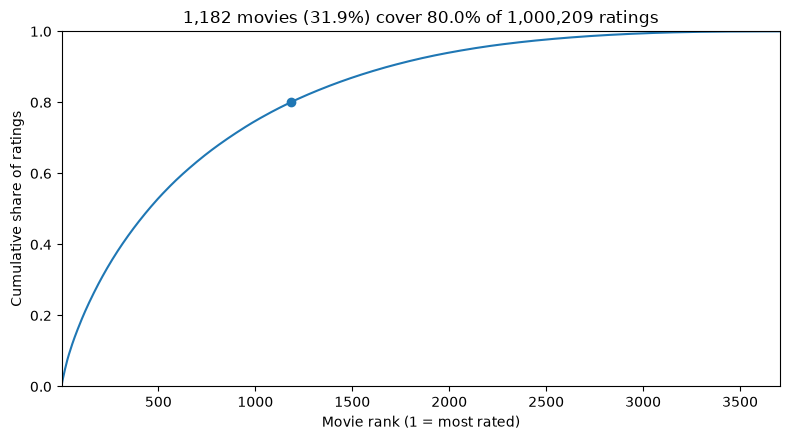

In [4]:
import matplotlib.pyplot as plt

ranked_counts = np.sort(movie_counts)[::-1]  # (n_movies,)
n_movies = int(ranked_counts.shape[0])
cumulative_counts = np.cumsum(ranked_counts)  # (n_movies,)
total_ratings = int(cumulative_counts[-1])
cumulative_share = cumulative_counts / total_ratings  # (n_movies,)
assert total_ratings == int(movie_counts.sum())

head_shares = np.array([0.01, 0.10, 0.20])  # (3,)
head_counts = np.ceil(head_shares * n_movies).astype(np.int64)  # (3,)
held_shares = cumulative_share[head_counts - 1]  # (3,)

coverage = 0.80
n_cover = int(np.searchsorted(cumulative_share, coverage, side="left")) + 1
assert 1 <= n_cover <= n_movies

print(f"{n_movies:,} rated movies, {total_ratings:,} ratings")
for share, count, held in zip(head_shares, head_counts, held_shares, strict=True):
    print(
        f"top {share:.0%} of movies ({int(count):,}) hold {held:.1%} of ratings"
    )
print(
    f"{n_cover:,} movies ({n_cover / n_movies:.1%}) cover {coverage:.0%} of ratings"
)

rank = np.arange(1, n_movies + 1)  # (n_movies,)
fig, ax = plt.subplots(figsize=(8, 4.5))
(line,) = ax.plot(rank, cumulative_share)
ax.scatter(
    [n_cover],
    [cumulative_share[n_cover - 1]],
    color=line.get_color(),
    zorder=3,
)
ax.set_xlim(1, n_movies)
ax.set_ylim(0, 1)
ax.set_xlabel("Movie rank (1 = most rated)")
ax.set_ylabel("Cumulative share of ratings")
ax.set_title(
    f"{n_cover:,} movies ({n_cover / n_movies:.1%}) cover "
    f"{cumulative_share[n_cover - 1]:.1%} of {total_ratings:,} ratings"
)
fig.tight_layout()


## Ratings per user

One user holds a count of ratings: how many movies that user scored. The fact is that count, in ratings.

The summary is the minimum, the quartiles, the mean, the 90th and 99th percentiles, and the maximum. The histogram uses log-spaced bins on a log x axis, because a linear axis would squeeze the short counts into one bar and hide the long right tail.


6,040 users
min 20
25th percentile 44
median 96
mean 165.6
75th percentile 208
90th percentile 400
99th percentile 906.66
max 2,314


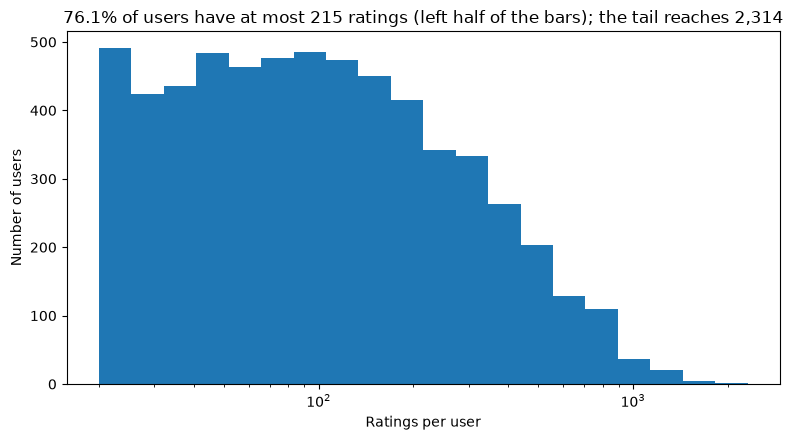

In [5]:
import matplotlib.pyplot as plt

assert user_counts.shape == (dataset.n_users,)
n_users = int(user_counts.shape[0])
percentiles = np.percentile(user_counts, [0, 25, 50, 75, 90, 99, 100])  # (7,)
count_min, q1, median, q3, p90, p99, count_max = (float(v) for v in percentiles)
mean_count = float(user_counts.mean())
assert count_max > count_min > 0


def format_count(value: float) -> str:
    """Print a whole count as an integer and any other value to two decimals."""
    if value.is_integer():
        return f"{int(value):,}"
    return f"{value:,.2f}"


print(f"{n_users:,} users")
print(f"min {format_count(count_min)}")
print(f"25th percentile {format_count(q1)}")
print(f"median {format_count(median)}")
print(f"mean {mean_count:,.1f}")
print(f"75th percentile {format_count(q3)}")
print(f"90th percentile {format_count(p90)}")
print(f"99th percentile {format_count(p99)}")
print(f"max {format_count(count_max)}")

n_bins = 20
bin_edges = np.logspace(np.log10(count_min), np.log10(count_max), n_bins + 1)  # (n_bins + 1,)
# Snap the ends so the minimum and the maximum fall inside the bars.
bin_edges[0] = count_min
bin_edges[-1] = count_max

fig, ax = plt.subplots(figsize=(8, 4.5))
hist_counts, _, _ = ax.hist(user_counts, bins=bin_edges)
assert int(hist_counts.sum()) == n_users
half = n_bins // 2
split = float(bin_edges[half])
left_counts = user_counts[user_counts < split]  # users in the left half of the bars
n_left = int(left_counts.shape[0])
left_max = int(left_counts.max())
assert n_left == int(hist_counts[:half].sum())
ax.set_xscale("log")
ax.set_xlabel("Ratings per user")
ax.set_ylabel("Number of users")
ax.set_title(
    f"{n_left / n_users:.1%} of users have at most {left_max:,} ratings "
    f"(left half of the bars); the tail reaches {count_max:,.0f}"
)
fig.tight_layout()


## Cold start

Cold start is an entity the model has not seen, or has barely seen. Each figure below is a count of movies or a count of users.

- Catalog: a movie in `movies.dat`, or a user in `users.dat`, with no rating. `Dataset` leaves those IDs out of its index, because the index includes only IDs that appear in the ratings.
- Low activity: a rated movie, or a user, with fewer than 5, 10, or 20 ratings. These counts use `movie_counts` and `user_counts`, so a catalog movie with zero ratings is not included.
- Split: the default `temporal_split` holds out each user's latest ratings, the last 20% as test and the last 10% of what remains as validation. A cold entity appears in validation or in test and never appears in train. The row count is how many ratings in that piece belong to such an entity.

In [6]:
from rec_engine import temporal_split
from rec_engine.dataset import read_table

user_table = read_table(
    data_dir / "users.dat",
    ("user_id", "gender", "age", "occupation", "zip_code"),
    dtype={"zip_code": str},
)
movie_table = read_table(
    data_dir / "movies.dat",
    ("movie_id", "title", "genres"),
)
catalog_user_ids = np.unique(user_table["user_id"].to_numpy())  # (n_catalog_users,)
catalog_movie_ids = np.unique(movie_table["movie_id"].to_numpy())  # (n_catalog_movies,)
assert np.isin(dataset.user_ids, catalog_user_ids).all()
assert np.isin(dataset.movie_ids, catalog_movie_ids).all()

n_unrated_users = int((~np.isin(catalog_user_ids, dataset.user_ids)).sum())
n_unrated_movies = int((~np.isin(catalog_movie_ids, dataset.movie_ids)).sum())

thresholds = np.array([5, 10, 20], dtype=np.int64)  # (3,)
# Each row is one threshold. The count vectors cover rated entities only.
movies_below = (movie_counts < thresholds[:, None]).sum(axis=1)  # (3,)
users_below = (user_counts < thresholds[:, None]).sum(axis=1)  # (3,)
assert movies_below.shape == users_below.shape == thresholds.shape

split = temporal_split(dataset)
n_train = int(split.train.shape[0])
n_val = int(split.val.shape[0])
n_test = int(split.test.shape[0])
assert n_train + n_val + n_test == len(dataset)


def unseen_in_train(row_indices: np.ndarray, train_ids: np.ndarray) -> tuple[int, int]:
    """Count distinct ids, and rows, that never appear in ``train_ids``.

    ``row_indices`` is the entity index of each validation or test row,
    shape ``(n_rows,)``. ``train_ids`` is the distinct entity indices in
    train, shape ``(n_train_entities,)``.
    """
    unseen = ~np.isin(row_indices, train_ids)  # (n_rows,)
    cold_ids = row_indices[unseen]  # (n_cold_rows,)
    return int(np.unique(cold_ids).shape[0]), int(cold_ids.shape[0])


train_movie_indices = np.unique(dataset.movie_indices[split.train])  # (n_train_movies,)
train_user_indices = np.unique(dataset.user_indices[split.train])  # (n_train_users,)
val_cold_movies, val_cold_movie_rows = unseen_in_train(
    dataset.movie_indices[split.val], train_movie_indices
)
test_cold_movies, test_cold_movie_rows = unseen_in_train(
    dataset.movie_indices[split.test], train_movie_indices
)
val_cold_users, val_cold_user_rows = unseen_in_train(
    dataset.user_indices[split.val], train_user_indices
)
test_cold_users, test_cold_user_rows = unseen_in_train(
    dataset.user_indices[split.test], train_user_indices
)

print(
    f"catalog: {n_unrated_movies:,} movies in movies.dat have no rating; "
    f"{n_unrated_users:,} users in users.dat have no rating"
)
print("low activity, among rated movies and users:")
for threshold, n_movies_below, n_users_below in zip(
    thresholds, movies_below, users_below, strict=True
):
    print(
        f"  fewer than {int(threshold)} ratings: "
        f"{int(n_movies_below):,} movies, {int(n_users_below):,} users"
    )
print(
    f"split, default temporal_split "
    f"({n_train:,} train, {n_val:,} validation, {n_test:,} test rows):"
)
print(
    f"  validation movies never in train: {val_cold_movies:,} movies, "
    f"{val_cold_movie_rows:,} rows of {n_val:,}"
)
print(
    f"  test movies never in train: {test_cold_movies:,} movies, "
    f"{test_cold_movie_rows:,} rows of {n_test:,}"
)
print(
    f"  validation users never in train: {val_cold_users:,} users, "
    f"{val_cold_user_rows:,} rows of {n_val:,}"
)
print(
    f"  test users never in train: {test_cold_users:,} users, "
    f"{test_cold_user_rows:,} rows of {n_test:,}"
)

catalog: 177 movies in movies.dat have no rating; 0 users in users.dat have no rating
low activity, among rated movies and users:
  fewer than 5 ratings: 290 movies, 0 users
  fewer than 10 ratings: 446 movies, 0 users
  fewer than 20 ratings: 663 movies, 0 users
split, default temporal_split (724,973 train, 77,580 validation, 197,656 test rows):
  validation movies never in train: 12 movies, 12 rows of 77,580
  test movies never in train: 42 movies, 59 rows of 197,656
  validation users never in train: 0 users, 0 rows of 77,580
  test users never in train: 0 users, 0 rows of 197,656


User cold start is absent by construction, and item cold start is real but small. GroupLens built MovieLens 1M from users with at least 20 ratings, and the default `temporal_split` holds out later ratings of each of those users, so validation and test contain no user who is missing from train. Movies are not guaranteed a train row: the catalog includes movies with no rating, some rated movies have only a few ratings, and a small number of validation and test movies never appear in train.